### Linear regression/diagnostics/cross validation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import ShuffleSplit
from sklearn.model_selection import KFold
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn import linear_model
from sklearn.linear_model import LinearRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.multiclass import OneVsOneClassifier
from sklearn.metrics import ConfusionMatrixDisplay

import statsmodels.api as sm
import seaborn as sns

from scipy import stats

In [3]:
data = pd.read_csv("dataset_2191_sleep.csv")
#clean data: drop question mark values
data = data[(data['max_life_span'] != '?') & (data['total_sleep'] != '?')]
data.info()

<class 'pandas.DataFrame'>
Index: 54 entries, 0 to 60
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   body_weight           54 non-null     float64
 1   brain_weight          54 non-null     float64
 2   max_life_span         54 non-null     str    
 3   gestation_time        54 non-null     str    
 4   predation_index       54 non-null     int64  
 5   sleep_exposure_index  54 non-null     int64  
 6   danger_index          54 non-null     int64  
 7   total_sleep           54 non-null     str    
dtypes: float64(2), int64(3), str(3)
memory usage: 3.8 KB


In [4]:
#convert strings to floats
data["max_life_span"] = data["max_life_span"].astype(float)
data["total_sleep"] = data["total_sleep"].astype(float)
data.info()

<class 'pandas.DataFrame'>
Index: 54 entries, 0 to 60
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   body_weight           54 non-null     float64
 1   brain_weight          54 non-null     float64
 2   max_life_span         54 non-null     float64
 3   gestation_time        54 non-null     str    
 4   predation_index       54 non-null     int64  
 5   sleep_exposure_index  54 non-null     int64  
 6   danger_index          54 non-null     int64  
 7   total_sleep           54 non-null     float64
dtypes: float64(4), int64(3), str(1)
memory usage: 3.8 KB


In [5]:
#define dependent and independent variables for later use
max_life_span = data["max_life_span"]
sleep_time = data["total_sleep"]

In [6]:
#split data

X_train, X_test, y_train, y_test = train_test_split(sleep_time, max_life_span, test_size=0.3, random_state=42)
#convert everything to numpy
X_train = X_train.to_numpy()
y_test = y_test.to_numpy()
y_train = y_train.to_numpy()
X_test = X_test.to_numpy()

#fix dimensions to make this work
X_test = X_test.reshape(-1, 1)
X_train = X_train.reshape(-1, 1)
y_train = y_train.reshape(-1, 1)

In [7]:
# Make sure dependent variables are 1D
y_train = y_train.ravel()
y_test = y_test.ravel()

In [8]:
#since X_train is only 35 -> chose k = 2 so that each time the model runs there is at least some meaningful amount of data
k = 2
kf = KFold(n_splits=k,shuffle=True,random_state=42)

In [9]:
#train model 
mse_ols_results = []


for (train, val) in kf.split(X_train):
    x_t, y_t = X_train[train], y_train[train]
    x_v, y_v = X_train[val], y_train[val]
    
    model1 = LinearRegression()
    model1.fit(x_t, y_t)

    # Predict on the validation observations
    predictions = model1.predict(x_v)
    
    # Calculate validation MSE
    mse = mean_squared_error(y_v, predictions)

    mse_ols_results.append(mse)

print(f"MSE from each fold: {mse_ols_results}")

MSE from each fold: [481.85459458123154, 200.68479859976387]


In [11]:
#average MSE from this model
avg_mse = sum(mse_ols_results)/len(mse_ols_results)
print(avg_mse)

341.2696965904977


In [12]:
#test model
#scikitlearn is being annoying, reshape other variables now as well
#run linear regression on the training data now:
model1.fit(X_train, y_train)

y_predicted = model1.predict(X_test)
test_mse = mean_squared_error(y_test, y_predicted)
print(test_mse)

289.7018706576074


In [13]:
slope = model1.coef_[0]
intercept = model1.intercept_

print(slope)
print(intercept)

-1.5265678243751688
34.33764594769425


In [19]:
sleep_time.shape

(54,)

Text(0.5, 1.0, 'Predictions on test data')

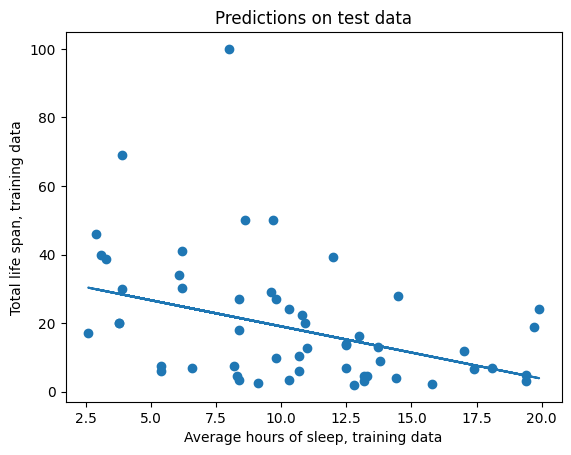

In [23]:
y = slope *X_train + intercept

plt.scatter(sleep_time, max_life_span)
plt.plot(X_train, y)
plt.xlabel("Average hours of sleep, training data")
plt.ylabel("Total life span, training data")
plt.title("Predictions on test data")

##### Comparison of predicted and actual values of test data

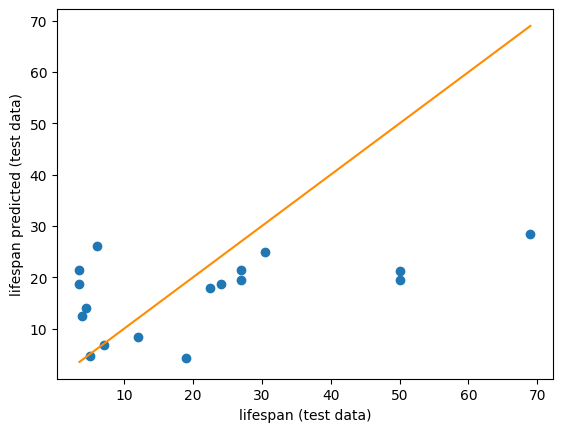

In [73]:
plt.scatter(y_test, y_predicted)
plt.xlabel("lifespan (test data)")
plt.ylabel("lifespan predicted (test data)")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='darkorange') #reference line


##### Diagnostics on model - ran on TRAINING data

In [41]:
def least_squares_diagnostics_train(X_train,y_train):
    model1.fit(X_train, y_train)

    y_predicted = model1.predict(X_train)
    train_mse = mean_squared_error(y_train, y_predicted)

    #calculate ideal y values
    yhat = y_predicted
    #yhat = model.predict(X)
    #residuals: 
    residuals = y_train - y_predicted
    #calculate influence

    # calculate leverages
    H = X_train @ np.linalg.pinv(X_train.T @ X_train) @ X_train.T
    h_ii = np.diag(H) #leverages
    #calculate the standard residuals
    s_i = residuals / np.sqrt(train_mse * (1- h_ii)) #standard residuals
    
    #calculate cook's distance
    n = X_train.shape[0]
    p = X_train.shape[1]
    dof = n-p
    cook_distance = (s_i ** 2/p) * h_ii/(1-h_ii)
    
    
    #influence = model1.get_influence()
    #s_i = influence.resid_studentized_external # standard residuals
    #h_ii = influence.hat_matrix_diag # leverages
    h_grid = np.linspace(np.min(h_ii),np.max(h_ii),100)
    

    #specifications for degrees of freedom
    #n, p = X.shape
    #n, p = X_test.shape
    #dof = n - p # degrees of freedom
    l_thr = 2*p/n # leverage threshold
    d_thr = 4.0 /dof # cook's distance threshold
    s_cook = np.sqrt(d_thr * p * (1-h_grid) / h_grid)

    
#plotting
    fig, ax = plt.subplots(4,1,sharex=False,sharey=False, figsize=(6,15))

    plt.suptitle('Least squares diagnostics - on training data')
    # residual plot
    #ADD THE HORIZONTAL BAR
    ax[0].set_title('Residuals')
    ax[0].scatter(y, residuals, alpha =0.7, color = 'black')
    ax[0].hlines(0,np.min(y),np.max(y),linewidth=2, color = 'hotpink')
    ax[0].set_xlabel('maximum lifespan')
    ax[0].set_ylabel('Residuals')

    # q-q plot
    osm, osr = stats.probplot(s_i,dist='t',fit=False,sparams=(n-p-1))
    ax[2].set_title('Q-Q')
    ax[2].scatter(osm,osr, color = 'black', alpha =0.7)
    ax[2].plot(osm,osm, linewidth = 2, color = 'mediumseagreen')
    ax[2].set_xlabel('Theoretical quantile')
    ax[2].set_ylabel('Real quantile')
    
    # scale-location plot
    ax[1].set_title('Scale-location')
    ax[1].scatter(yhat,np.sqrt(abs(s_i)), color = 'black', alpha =0.7)
    ax[1].set_xlabel('Predicted values')
    ax[1].set_ylabel('|Std. Res.|$^{1/2}$')
    
    # residuals vs leverage plot
    ax[3].set_title('Residuals vs leverage')
    ax[3].scatter(h_ii,s_i, alpha =0.7, color = 'black')
    if( np.min(s_cook) < np.max(s_i) or np.max(-s_cook) > np.min(s_i) ):
        plt.plot(h_grid,s_cook, color = 'darkorange', linewidth = 2)
        plt.plot(h_grid,-s_cook, color = 'darkorange', linewidth = 2)
    if( l_thr < 1.1 * np.max(h_ii) ):
        plt.vlines(l_thr,np.min(s_i),np.max(s_i), color = 'royalblue', linewidth = 2)
    if( np.max(s_i) > 2.5 or np.min(s_i) < -2.5 ):
        plt.hlines([-3,3],np.min(h_ii),np.max(h_ii),color = 'royalblue', linewidth = 2)
    ax[3].set_xlabel('Leverage')
    ax[3].set_ylabel('Std. Res.')

    
    plt.tight_layout()
    plt.show()

    return

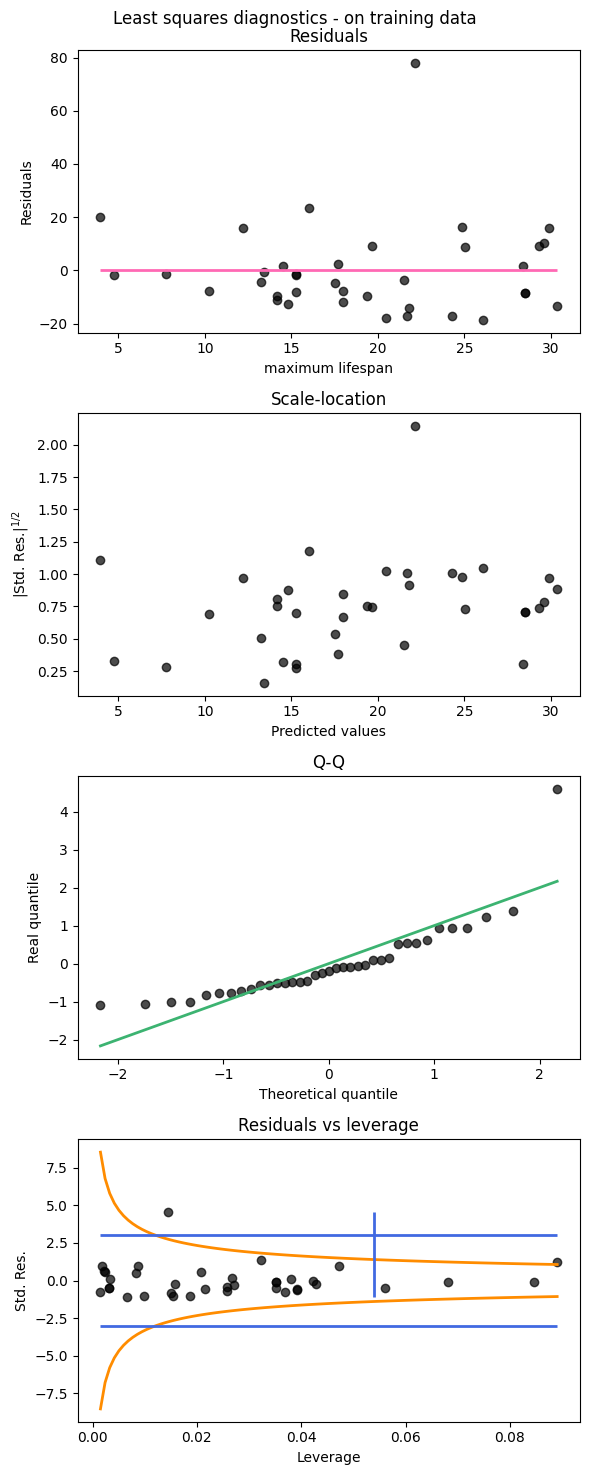

In [42]:
least_squares_diagnostics_train(X_train, y_train)

##### Diagnostics on TEST data

In [71]:
def least_squares_diagnostics_test(X_train,y_train):
    model1.fit(X_train, y_train)

    y_predicted_test = model1.predict(X_test)
    test_mse = mean_squared_error(y_test, y_predicted)

    #calculate ideal y values
    yhat = y_predicted_test
    #yhat = model.predict(X)
    #residuals: 
    test_residuals = y_test - y_predicted_test
    #calculate influence

    # calculate leverages
    H_test = X_test @ np.linalg.pinv(X_test.T @ X_test) @ X_test.T
    h_ii_test = np.diag(H_test) #leverages
    #calculate the standard residuals
    test_s_i = test_residuals / np.sqrt(test_mse * (1- h_ii_test)) #standard residuals
    
    #calculate cook's distance
    n = X_train.shape[0]
    p = X_train.shape[1]
    dof = n-p
    cook_distance = (test_s_i ** 2/p) * h_ii_test/(1-h_ii_test)
    
    
    #influence = model1.get_influence()
    #s_i = influence.resid_studentized_external # standard residuals
    #h_ii = influence.hat_matrix_diag # leverages
    h_grid = np.linspace(np.min(h_ii_test),np.max(h_ii_test),100)
    

    #specifications for degrees of freedom
    #n, p = X.shape
    #n, p = X_test.shape
    #dof = n - p # degrees of freedom
    l_thr = 2*p/n # leverage threshold
    d_thr = 4.0 /dof # cook's distance threshold
    s_cook = np.sqrt(d_thr * p * (1-h_grid) / h_grid)

    
#plotting
    fig, ax = plt.subplots(4,1,sharex=False,sharey=False, figsize=(6,15))

    plt.suptitle('Least squares diagnostics - on training data')
    # residual plot
    #ADD THE HORIZONTAL BAR
    ax[0].set_title('Residuals')
    ax[0].scatter(y_test, test_residuals, alpha =0.7, color = 'black')
    ax[0].hlines(0,np.min(y),np.max(y),linewidth=2, color = 'hotpink')
    ax[0].set_xlabel('maximum lifespan')
    ax[0].set_ylabel('Residuals')

    # q-q plot
    osm, osr = stats.probplot(test_s_i,dist='t',fit=False,sparams=(n-p-1))
    ax[2].set_title('Q-Q')
    ax[2].scatter(osm,osr, color = 'black', alpha =0.7)
    ax[2].plot(osm,osm, linewidth = 2, color = 'mediumseagreen')
    ax[2].set_xlabel('Theoretical quantile')
    ax[2].set_ylabel('Real quantile')
    
    # scale-location plot
    ax[1].set_title('Scale-location')
    ax[1].scatter(yhat,np.sqrt(abs(test_s_i)), color = 'black', alpha =0.7)
    ax[1].set_xlabel('Predicted values')
    ax[1].set_ylabel('|Std. Res.|$^{1/2}$')
    
    # residuals vs leverage plot
    ax[3].set_title('Residuals vs leverage')
    ax[3].scatter(h_ii_test,test_s_i, alpha =0.7, color = 'black')
    if( np.min(s_cook) < np.max(test_s_i) or np.max(-s_cook) > np.min(test_s_i) ):
        plt.plot(h_grid,s_cook, color = 'darkorange', linewidth = 2)
        plt.plot(h_grid,-s_cook, color = 'darkorange', linewidth = 2)
    if( l_thr < 1.1 * np.max(h_ii_test) ):
        plt.vlines(l_thr,np.min(test_s_i),np.max(test_s_i), color = 'royalblue', linewidth = 2)
    if( np.max(test_s_i) > 2.5 or np.min(test_s_i) < - 2.5 ):
        plt.hlines([-3,3],np.min(h_ii_test),np.max(h_ii_test),color = 'royalblue', linewidth = 2)
    ax[3].set_xlabel('Leverage')
    ax[3].set_ylabel('Std. Res.')

    
    plt.tight_layout()
    plt.show()

    return

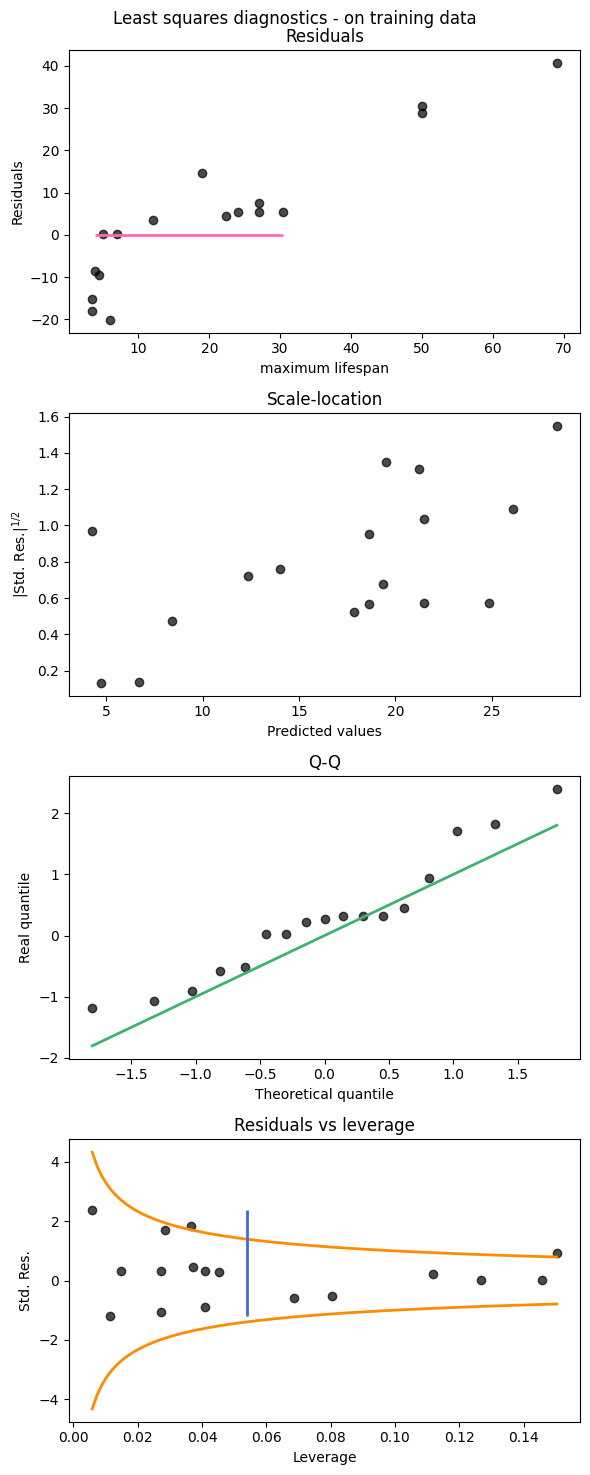

In [72]:
least_squares_diagnostics_test(X_train, y_train)